# Add decay heat

[Add point kinetics, feedback and a trip](add-point-kinetics-and-a-trip.ipynb) builds a kinetics node and leaves its `power_input` open. This page builds a decay-heat function in watts from a supplied fission-product table, plots it beside the lingering fissions over an hour, and wires it into a kinetics node that scrams at 10 s. The physics of every term is on [Decay Heat](../decay_heat.rst).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import rc

rc("font", family="serif", size=15)

from stream import Aggregator
from stream.calculations.point_kinetics import PointKineticsWInput, ReactivityController
from stream.composition import point_kinetics_steady_state
from stream.examples.lofa.params import BETA, GENERATION_TIME, LAMBDA
from stream.physical_models.decay_heat import fission_products, fissions
from stream.physical_models.decay_heat.fission_products import Source, Standard, fp_inner_
from stream.units import hour
from stream.utilities import identity

## The fission products, from a supplied table

`fission_products.contribution(standard, source)` reads a standard's table from a CSV file in the package's `standards` directory, named after the pair (`U235_ans14.csv` for `Source.U235` and `Standard.ANS14`), with a column `alpha` in MeV/s per fission and a column `lamda` in 1/s. Those files ship empty, so every pair raises `FileNotFoundError`. Without a table, call the sum itself: `fp_inner_(t, T, lamda, alpha)` takes the two columns as arrays and returns MeV per fission. Its `t` is the time after shutdown and its `T` the operation time before it, both in seconds; `T` is never a temperature, although on the kinetics node the same letter carries the feedback temperatures.

MeV per fission becomes watts through the fission rate $P_0 / Q$, with $Q$ = 200 MeV recoverable per fission. Without it the function returns MeV per fission, which the node adds to watts without complaint. The table below is illustrative, not a standard.

In [2]:
try:
    fission_products.contribution(Standard.ANS14, Source.U235)
except FileNotFoundError as err:
    print(f"contribution:   {err}")

P0 = 1e6
Q = 200.0
T_OP = 30 * 24 * hour
LAMDA = np.array([1e-1, 1e-3, 1e-5])
ALPHA = np.array([0.6, 4e-3, 3e-5])


def dh(t):
    return (P0 / Q * fp_inner_(t, T_OP, LAMDA, ALPHA)).item()


print(f"dh at shutdown: {dh(0.0) / 1e3:.1f} kW, {dh(0.0) / P0 * 100:.2f} % of P0")

contribution:   Does not vendor U235 from ANS14
dh at shutdown: 65.0 kW, 6.50 % of P0


The table gives 6.5 % of the power at shutdown after thirty days of operation. `.item()` makes the one-element array a plain float. An activated structure takes the same route: `activation.profile(lamda)` is a shape, 1 at shutdown after long operation, and needs an energy per fission before the factor $P_0 / Q$.

## The lingering fissions

`fissions.profile` takes a time grid, the generation time, the delayed-neutron fractions and decay rates, and a controller; it solves a kinetics node once on that grid from a critical start, its clock the time after shutdown, and returns the power over its starting value: a shape, not watts. Here the rods are 5 dollars driven in over 0.5 s. The profile interpolates its grid, holds the last value past its end, and ignores its `T`. `fissions.profile_from_pk(time, pk)` reads the same constants off a node and hands the profile's solve the node's own controller object, so its scram time and state machine act in that solve before the node's own run; pass `fissions.profile` a controller of its own instead.

                      fission products [% of P0]  lingering fissions [% of P0]
time after scram [s]                                                          
1.0                                       6.2125                       12.5543
60.0                                      3.3901                        1.0207
600.0                                     2.5887                        0.0004
3600.0                                    1.5016                        0.0000


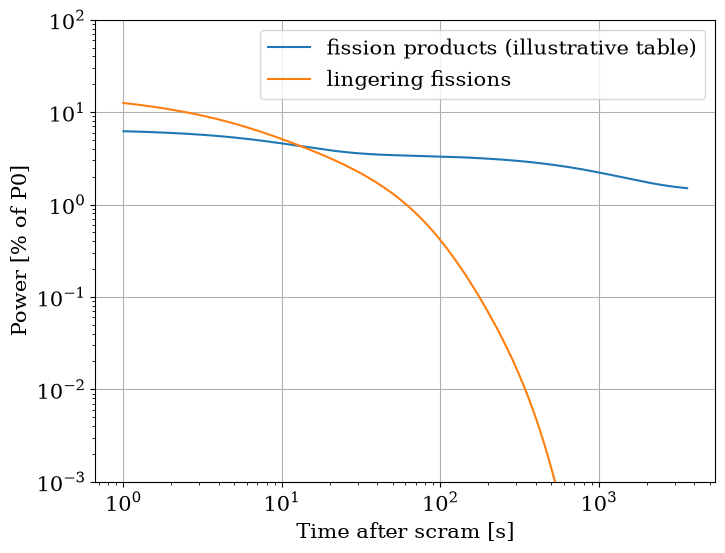

In [3]:
DOLLAR = float(np.sum(BETA))


def rods(t):
    return -5.0 * DOLLAR * min(max(t, 0.0) / 0.5, 1.0)


grid = np.concatenate([[0.0], np.geomspace(1e-3, hour, 400)])
shape = fissions.profile(grid, GENERATION_TIME, BETA, LAMBDA,
                         controls=ReactivityController(input_reactivity=lambda state, t_state, t: rods(t)))

t = np.geomspace(1.0, hour, 300)
fp_pct = np.array([dh(s) for s in t]) / P0 * 100
fis_pct = (P0 - dh(0.0)) * shape(t) / P0 * 100
marks = [1.0, 60.0, 600.0, hour]
print(pd.DataFrame({"fission products [% of P0]": [dh(s) / P0 * 100 for s in marks],
                    "lingering fissions [% of P0]": [(P0 - dh(0.0)) * shape(s) / P0 * 100 for s in marks]},
                   index=pd.Index(marks, name="time after scram [s]")).round(4))

fig, ax = plt.subplots(figsize=(8, 6))
ax.loglog(t, fp_pct, label="fission products (illustrative table)")
ax.loglog(t[fis_pct > 0], fis_pct[fis_pct > 0], label="lingering fissions")
ax.set_xlabel("Time after scram [s]")
ax.set_ylabel("Power [% of P0]")
ax.set_ylim(1e-3, 100)
ax.grid()
ax.legend()
plt.show()

The lingering fissions make about 12.6 % against the fission products' 6.2 % at 1 s, about 1.0 % against 3.4 % at a minute, and under 0.001 % at ten minutes; the fission products still make about 1.5 % at an hour. The profile sets values below 1e-12 of its start to zero, hence the 0.0000 and the plot's filter on positive points.

A kinetics node already integrates the chain reaction, so `power_input` takes the fission products alone and the lingering fissions come from the node's own rows. A fuel with no kinetics node takes the sum of both curves as its `power` schedule.

## Wire it into the kinetics node

[Feedback and outside power](add-point-kinetics-and-a-trip.ipynb#Feedback-and-outside-power) sets out the row that adds `power_input` to the fission power and the seed on the difference. The decay-heat function counts from the scram, so it is bound as `lambda t: dh(max(t - T_TRIP, 0.0))`: constant before the trip, which lets the seed be a root, and decaying after it. A function bound at bare `t` starts decaying before the reactor shuts down. For a trip a run detects, as on the previous page, `T_TRIP` is `ctrl.log[-1][1]` after the stop.

In [4]:
T_TRIP = 10.0
ctrl = ReactivityController(input_reactivity=lambda state, t_state, t: rods(t - T_TRIP))
pk = PointKineticsWInput(GENERATION_TIME, BETA, LAMBDA, controls=ctrl)
agr = Aggregator.from_decoupled(pk, funcs={pk: {"t": identity, "power_input": lambda t: dh(max(t - T_TRIP, 0.0))}})
y0 = agr.load(point_kinetics_steady_state(pk, P0, power_input=dh(0.0)))
sol = agr.solve(y0, np.linspace(0.0, 60.0, 121))

power = agr.at_times(sol, pk, "power")
pk_power = agr.at_times(sol, pk, "pk_power")
print(f"seed residual:          {np.linalg.norm(agr.compute(y0, 0.0)):.1e}")
print(f"power at 60 s:          {power[-1] / 1e3:.2f} kW")
print(f"power - pk_power:       {(power[-1] - pk_power[-1]) / 1e3:.4f} kW")
print(f"dh 50 s after the trip: {dh(50.0) / 1e3:.4f} kW")
print(f"pk_power over its seed: {pk_power[-1] / pk_power[0]:.6f}")
print(f"profile at 50 s:        {shape(50.0):.6f}")

seed residual:          4.3e-09
power at 60 s:          47.31 kW
power - pk_power:       34.2192 kW
dh 50 s after the trip: 34.2192 kW
pk_power over its seed: 0.014002
profile at 50 s:        0.014002


The seed is a root to about 4e-9. At 60 s the core makes about 47 kW, of which about 34 kW is the decay heat the function returns 50 s after the trip, and the fission rows have fallen to the profile's value at 50 s to every printed digit: the node computes the lingering fissions itself.

[Attaching the kinetics](../LOFABuildingTheLoop.ipynb#Attaching-the-kinetics) wires decay heat the same way on the pool reactor, a power-law fit counted from the low-flow trip, and [Power and reactivity](../LOFABothPumpsTrip.ipynb#Power-and-reactivity) in *Both Pumps Trip* shows the power settling onto it. [Get a steady solve to converge](get-a-steady-solve-to-converge.ipynb) is the next task.